## Ćwiczenie 9: usuwanie zakłóceń (Notch Filter)
**Cel:** Zastosowanie analizy widmowej do rozwiązania rzeczywistego problemu inżynierskiego – usunięcia sprzętowych pasów interferencyjnych z obrazu medycznego, których nie można usunąć klasycznymi filtrami przestrzennymi.

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import data, color, filters

plt.rcParams['figure.figsize'] = (10, 5)

#### Krok 1: Wczytanie danych (symulacja uszkodzonej aparatury)
Wczytamy zdrowy przekrój MRI, a następnie nałożymy na niego silne, prążkowane zakłócenie. Tego typu artefakty (pasy) często pojawiają się przy uszkodzeniach okablowania, złym uziemieniu skanera lub błędach matrycy.

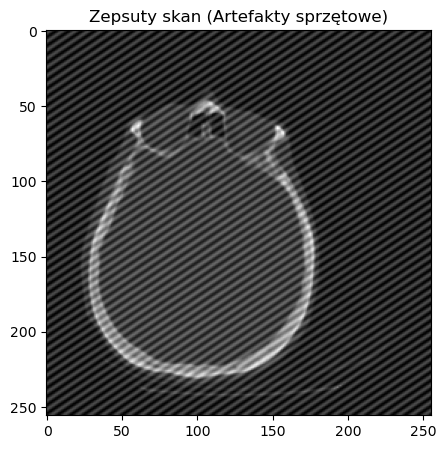

In [26]:
# Pobieramy obraz 256x256
clean_mri = data.brain()[1, :, :]

# Generujemy sztuczne zakłócenie (sinusoidalną siatkę ukośną)
rows, cols = clean_mri.shape
Y, X = np.indices((rows, cols))
# Częstotliwość zakłócenia
freq_y, freq_x = 45, 30 
noise_ampl = 0.2 * clean_mri.max()
noise = noise_ampl * np.sin(2 * np.pi * (freq_y * Y / rows + freq_x * X / cols))

# Dodajemy szum do obrazu i normalizujemy do przedziału [0, 1]
noisy_mri = clean_mri + noise
noisy_mri = (noisy_mri - noisy_mri.min()) / (noisy_mri.max() - noisy_mri.min())

plt.title('Zepsuty skan (Artefakty sprzętowe)')
plt.imshow(noisy_mri, cmap='gray')
plt.show()

#### Krok 2: Próba ratunku klasycznymi metodami 
Spróbujmy usunąć ostre krawędzie pasów klasycznym, silnym rozmyciem Gaussa.

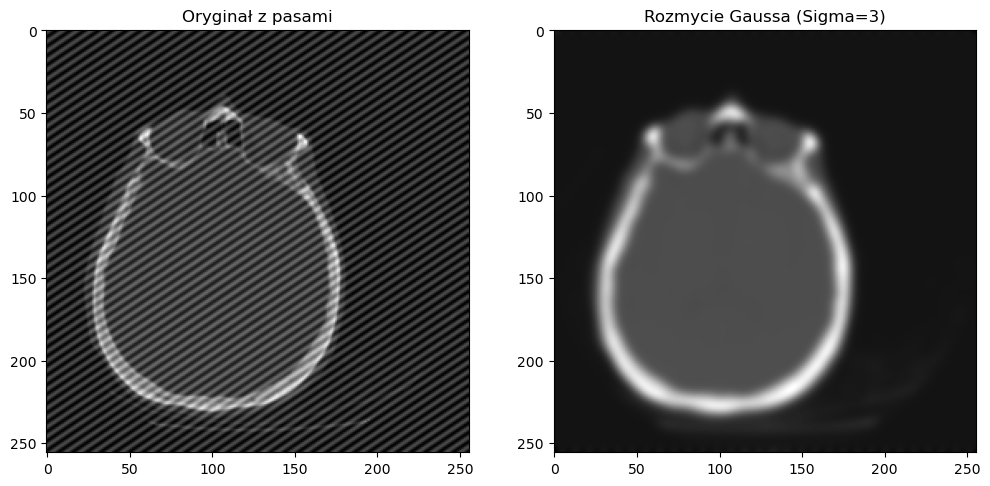

Wniosek: Filtr Gaussa musi być tak silny, by usunąć pasy, że przy okazji całkowicie zniszczył strukturę tkanki.


In [35]:
blurred_mri = filters.gaussian(noisy_mri, sigma=3)

fig, ax = plt.subplots(1, 2, figsize=(12, 6))
ax[0].imshow(noisy_mri, cmap='gray'); ax[0].set_title('Oryginał z pasami')
ax[1].imshow(blurred_mri, cmap='gray'); ax[1].set_title('Rozmycie Gaussa (Sigma=3)')
plt.show()

print("Wniosek: Filtr Gaussa musi być tak silny, by usunąć pasy, że przy okazji całkowicie zniszczył strukturę tkanki.")

#### Krok 3: Diagnoza w domenie częstotliwości (FFT)
**Zadanie:** Przejdź do dziedziny częstotliwości. Policz 2D FFT, wyśrodkuj je i wyświetl widmo amplitudowe w skali logarytmicznej.

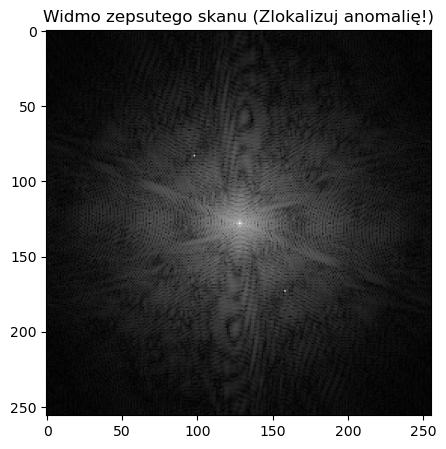

In [38]:
# ROZWIĄZANIE:
fft_result = np.fft.fft2(noisy_mri)
fft_shifted = np.fft.fftshift(fft_result)
magnitude_spectrum = np.log(1 + np.abs(fft_shifted))

plt.title('Widmo zepsutego skanu (Zlokalizuj anomalię!)')
plt.imshow(magnitude_spectrum, cmap='gray')
plt.show()

#### Krok 4: Filtr pasmowoprzepustowy (Notch Filter)
Spójrz na widmo powyżej. Widzisz dużą, białą gwiazdę na środku (to nasz pacjent). Zauważ jednak **dwie małe, bardzo jasne kropki**, ułożone symetrycznie na ukos od centrum. To właśnie one reprezentują całą siatkę pasków na oryginalnym zdjęciu!

**Zadanie:** 
1. Odczytaj (w przybliżeniu, najeżdżając kursorem na wykresie lub wyliczając matematycznie ze współrzędnych z kroku 1) położenie (y, x) tych dwóch kropek.
2. Stwórz maskę, która jest wszędzie równa 1 (przepuszcza wszystko), ale w miejscu tych dwóch kropek (np. w małym promieniu r=3 wokół nich) ma wartość 0 (odcięcie).

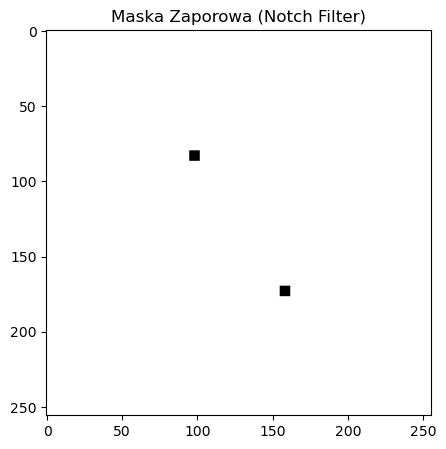

In [52]:
# Tworzymy maskę złożoną z samych jedynek
notch_mask = np.ones_like(noisy_mri)

# Środek macierzy (dla obrazu 256x256 to punkt [128, 128])
center_y, center_x = rows // 2, cols // 2

# ROZWIĄZANIE:
freq_y, freq_x = 45, 30 

# Pik 1 (Dolny Prawy)
p1_y, p1_x = center_y + freq_y, center_x + freq_x
# Pik 2 (Górny Lewy)
p2_y, p2_x = center_y - freq_y, center_x - freq_x

# Wycinamy prostokąty 7x7 wokół pików, zerując je
r = 3
notch_mask[p1_y-r:p1_y+r+1, p1_x-r:p1_x+r+1] = 0
notch_mask[p2_y-r:p2_y+r+1, p2_x-r:p2_x+r+1] = 0

plt.title('Maska Zaporowa (Notch Filter)')
plt.imshow(notch_mask, cmap='gray')
plt.show()

#### Krok 5: Rekonstrukcja obrazu
Teraz połączymy maskę z widmem (mnożenie), by fizycznie wyzerować sygnał błędu, a następnie zrekonstruujemy obraz operacją IFFT.

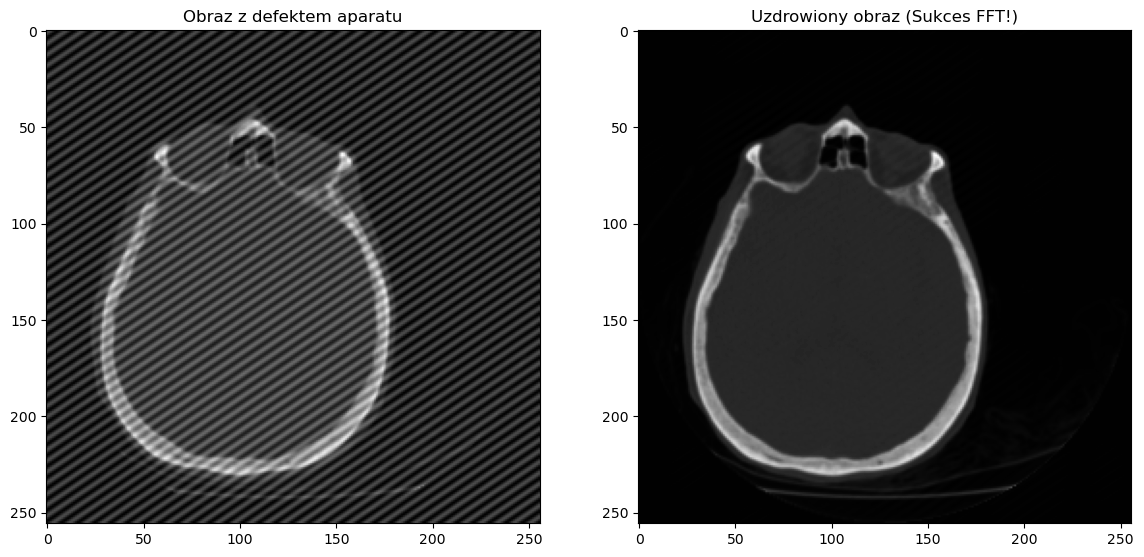

In [55]:
# 1. Usunięcie wadliwych fal
filtered_fft_shifted = fft_shifted * notch_mask

# ROZWIĄZANIE:
fft_ishift = np.fft.ifftshift(filtered_fft_shifted)
cleaned_mri = np.abs(np.fft.ifft2(fft_ishift))

# WIZUALIZACJA KOŃCOWA
fig, ax = plt.subplots(1, 2, figsize=(14, 7))
ax[0].imshow(noisy_mri, cmap='gray'); ax[0].set_title('Obraz z defektem aparatu')
ax[1].imshow(cleaned_mri, cmap='gray'); ax[1].set_title('Uzdrowiony obraz (Sukces FFT!)')
plt.show()